# Introduction
In this dataset the number of closed stores is greater than the number of open shops so I do some feature engineering to have more information about the closed stores and holidays. Also, the feature named promo2 has a strong effet on sales.

**Downloading the dataset**

In [12]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('rossmann-store-sales')

print("Path to competition files:", path)

Path to competition files: /kaggle/input/competitions/rossmann-store-sales


In [2]:
from pathlib import Path
import pandas as pd

def load_housing_data(x):
    return pd.read_csv(x, low_memory=False)

store= load_housing_data("/kaggle/input/competitions/rossmann-store-sales/store.csv")
train= load_housing_data("/kaggle/input/competitions/rossmann-store-sales/train.csv")
test= load_housing_data("/kaggle/input/competitions/rossmann-store-sales/test.csv")

In [29]:
train.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  object
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(2)
memory usage: 69.8+ MB


In [30]:
store.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   object 
 2   Assortment                 1115 non-null   object 
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    object 
dtypes: float64(5), int64(2), object(3)
memory usage: 87.2+ KB


In [7]:
train.isna().sum()          # or train.isnull().sum() — identical

Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

In [8]:
test["Open"] = test["Open"].fillna(-1).astype(int)
# missing -> -1, real -> 0 / 1
test["Open"].value_counts()
# test_t.info()

Open
 1    35093
 0     5984
-1       11
Name: count, dtype: int64

**Merge store columns into train and test sets**

In [5]:
# ==============================================================================
# MERGE STORE-LEVEL METADATA (incl. Promo2) INTO TRAIN AND TEST
# ==============================================================================
import numpy as np
import pandas as pd

# ------------------------------------------------------------------------------
# 0. INSPECT ALL THREE DATASETS
# ------------------------------------------------------------------------------
print("=" * 70)
print("BEFORE MERGE")
print("=" * 70)
print(f"train: shape={train.shape}, has Store={'Store' in train.columns}, "
      f"has Promo2={'Promo2' in train.columns}")
print(f"test:  shape={test.shape},  has Store={'Store' in test.columns},  "
      f"has Promo2={'Promo2' in test.columns}")
print(f"store: shape={store.shape}, has Store={'Store' in store.columns}")
print(f"\nstore columns: {store.columns.tolist()}")

# ------------------------------------------------------------------------------
# 1. ENSURE 'Store' IS THE SAME DTYPE ON ALL THREE
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("STORE DTYPE CHECK")
print("=" * 70)
print(f"train['Store'].dtype: {train['Store'].dtype}")
print(f"test['Store'].dtype:  {test['Store'].dtype}")
print(f"store['Store'].dtype: {store['Store'].dtype}")

# normalize all to the store dtype (safest: string)
target_dtype = store["Store"].dtype
train["Store"] = train["Store"].astype(target_dtype)
test["Store"]  = test["Store"].astype(target_dtype)

print("✅ aligned Store dtype to:", train["Store"].dtype)

# ------------------------------------------------------------------------------
# 2. PREPARE THE LOOKUP TABLE (one row per Store)
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("PREPARE LOOKUP")
print("=" * 70)

# columns to bring over — Promo2 always, plus any others you want
cols_to_bring = ["Store", "Promo2"]
# extra_cols = ["StoreType", "Assortment", "CompetitionDistance",
#               "PromoInterval"]                       # add/remove as you like
# for c in extra_cols:
#     if c in store.columns:
#         cols_to_bring.append(c)

print(f"columns to merge: {cols_to_bring}")

store_lookup = store[cols_to_bring].drop_duplicates("Store").copy()
print(f"store_lookup shape: {store_lookup.shape}  "
      f"(expected ~1115 rows)")

# sanity: no duplicate Store in lookup
assert store_lookup["Store"].is_unique, \
    "❌ store has duplicate Store values — fix before merging"

# ------------------------------------------------------------------------------
# 3. MERGE INTO TRAIN (and drop existing Promo2 first if present)
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("MERGE INTO TRAIN")
print("=" * 70)

# if train already has these columns from an earlier merge, drop them
existing = [c for c in cols_to_bring if c != "Store" and c in train.columns]
if existing:
    print(f"dropping existing columns from train to avoid duplicates: {existing}")
    train = train.drop(columns=existing)

n_before = len(train)
train = train.merge(store_lookup, on="Store", how="left")
assert len(train) == n_before, \
    f"❌ row count changed: {n_before} -> {len(train)} (duplicate Store in lookup)"

print(f"✅ train: {n_before} rows -> {len(train)} rows, "
      f"{train.shape[1]} columns")

# ------------------------------------------------------------------------------
# 4. MERGE INTO TEST
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("MERGE INTO TEST")
print("=" * 70)

existing = [c for c in cols_to_bring if c != "Store" and c in test.columns]
if existing:
    print(f"dropping existing columns from test to avoid duplicates: {existing}")
    test = test.drop(columns=existing)

n_before = len(test)
test = test.merge(store_lookup, on="Store", how="left")
assert len(test) == n_before, \
    f"❌ row count changed: {n_before} -> {len(test)} (duplicate Store in lookup)"

print(f"✅ test: {n_before} rows -> {len(test)} rows, "
      f"{test.shape[1]} columns")

# ------------------------------------------------------------------------------
# 5. VERIFY MERGE SUCCESS (no missing Promo2 where Store exists)
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("MERGE VALIDATION")
print("=" * 70)

for name, df in [("train", train), ("test", test)]:
    n_total = len(df)
    n_missing_promo2 = df["Promo2"].isna().sum()
    n_missing_store = df["Store"].isna().sum()
    print(f"\n{name}:")
    print(f"  rows:              {n_total}")
    print(f"  missing Promo2:    {n_missing_promo2} "
          f"({n_missing_promo2 / n_total * 100:.3f}%)")
    print(f"  missing Store:     {n_missing_store}")

    # show which stores failed to match
    if n_missing_promo2 > 0:
        bad_stores = df.loc[df["Promo2"].isna(), "Store"].unique()[:20]
        print(f"  ⚠️ stores with no Promo2 match: {bad_stores}")
    else:
        print("  ✅ all stores matched — Promo2 fully populated")

# ------------------------------------------------------------------------------
# 6. SHOW PROMO2 DISTRIBUTION (train vs test) — should be similar
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("PROMO2 DISTRIBUTION")
print("=" * 70)

promo2_summary = pd.DataFrame({
    "train": train["Promo2"].value_counts(normalize=True).sort_index(),
    "test":  test["Promo2"].value_counts(normalize=True).sort_index(),
}).round(4)
promo2_summary.index.name = "Promo2"
print(promo2_summary.to_string())
print("\n(If train/test differ a lot -> different store mix, expected in different time periods)")

# ------------------------------------------------------------------------------
# 7. CONFIRM 'Store' COLUMN EXISTS AND SAMPLE ROWS
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("SAMPLE ROWS")
print("=" * 70)
show_cols = ["Store", "Promo2"] + \
            [c for c in cols_to_bring if c not in ("Store", "Promo2")
             and c in train.columns]
print("\ntrain sample:")
print(train[show_cols].head().to_string(index=False))
print("\ntest sample:")
print(test[show_cols].head().to_string(index=False))

print("\n✅ Merge complete for both train and test.")

BEFORE MERGE
train: shape=(1017209, 9), has Store=True, has Promo2=False
test:  shape=(41088, 8),  has Store=True,  has Promo2=False
store: shape=(1115, 10), has Store=True

store columns: ['Store', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']

STORE DTYPE CHECK
train['Store'].dtype: int64
test['Store'].dtype:  int64
store['Store'].dtype: int64
✅ aligned Store dtype to: int64

PREPARE LOOKUP
columns to merge: ['Store', 'Promo2']
store_lookup shape: (1115, 2)  (expected ~1115 rows)

MERGE INTO TRAIN
✅ train: 1017209 rows -> 1017209 rows, 10 columns

MERGE INTO TEST
✅ test: 41088 rows -> 41088 rows, 9 columns

MERGE VALIDATION

train:
  rows:              1017209
  missing Promo2:    0 (0.000%)
  missing Store:     0
  ✅ all stores matched — Promo2 fully populated

test:
  rows:              41088
  missing Promo2:    0 (0.000%)
  missing Store:     0
  ✅ all sto

**Adding new holiday features**

In [6]:
# ==============================================================================
# 3. ADD HOLIDAY INTERACTION + IsSunday FEATURES
# ==============================================================================
# do this on BOTH train and test (same function for consistency)

def add_holiday_features(df):
    df = df.copy()

    # IsSunday
    if "dayofweek" in df.columns:
        df["IsSunday"] = (df["dayofweek"] == 6).astype(int)
    elif "DayOfWeek" in df.columns:
        df["IsSunday"] = (df["DayOfWeek"] == 7).astype(int)  # DayOfWeek 7=Sun
    elif "Date" in df.columns:
        df["IsSunday"] = (pd.to_datetime(df["Date"]).dt.dayofweek == 6).astype(int)

    # StateHoliday as int flag(s)
    if "StateHoliday" in df.columns:
        sh = df["StateHoliday"].astype(str)
        df["is_state_holiday"] = (sh != "0").astype(int)
        df["is_public_holiday"]  = (sh == "a").astype(int)
        df["is_easter_holiday"]  = (sh == "b").astype(int)
        df["is_christmas_holiday"] = (sh == "c").astype(int)

    # SchoolHoliday already 0/1 — keep as is

    # INTERACTIONS
    if "is_state_holiday" in df.columns and "StoreType" in df.columns:
        st = df["StoreType"].astype(str)
        for t in sorted(st.unique()):
            df[f"state_hol_x_store_{t}"] = df["is_state_holiday"] * (st == t).astype(int)

    if "is_state_holiday" in df.columns and "DayOfWeek" in df.columns:
        for d in sorted(df["DayOfWeek"].unique()):
            df[f"state_hol_x_dow_{d}"] = df["is_state_holiday"] * (df["DayOfWeek"] == d).astype(int)

    if "SchoolHoliday" in df.columns and "StoreType" in df.columns:
        st = df["StoreType"].astype(str)
        for t in sorted(st.unique()):
            df[f"school_hol_x_store_{t}"] = df["SchoolHoliday"] * (st == t).astype(int)

    if "IsSunday" in df.columns and "Promo" in df.columns:
        df["promo_x_sunday"] = df["Promo"] * df["IsSunday"]

    return df

# apply to BOTH
train = add_holiday_features(train_t)
test  = add_holiday_features(test_t)

print("\n" + "=" * 70)
print("NEW HOLIDAY FEATURES ADDED")
print("=" * 70)
new_holiday_cols = [c for c in train.columns
                    if any(k in c for k in ["IsSunday", "state_hol_x",
                                            "school_hol_x", "is_state_holiday",
                                            "is_public_holiday", "is_easter",
                                            "is_christmas_holiday",
                                            "promo_x_sunday"])]
print(f"{len(new_holiday_cols)} new features:")
for c in new_holiday_cols:
    print(f"  {c}")


NEW HOLIDAY FEATURES ADDED
0 new features:


In [7]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41088 entries, 0 to 41087
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Id                    41088 non-null  int64  
 1   Store                 41088 non-null  int64  
 2   DayOfWeek             41088 non-null  int64  
 3   Date                  41088 non-null  object 
 4   Open                  41077 non-null  float64
 5   Promo                 41088 non-null  int64  
 6   StateHoliday          41088 non-null  object 
 7   SchoolHoliday         41088 non-null  int64  
 8   IsSunday              41088 non-null  int64  
 9   is_state_holiday      41088 non-null  int64  
 10  is_public_holiday     41088 non-null  int64  
 11  is_easter_holiday     41088 non-null  int64  
 12  is_christmas_holiday  41088 non-null  int64  
 13  state_hol_x_dow_1     41088 non-null  int64  
 14  state_hol_x_dow_2     41088 non-null  int64  
 15  state_hol_x_dow_3  

**promo2 importance**

WORST vs BEST STORES — PROFILE COMPARISON
static store columns included in profile: ['StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2']

--- Per-store profile ---
       n_rows  n_open  open_rate  sales_mean  sales_std  sales_median  sales_cv  sales_min  sales_max  zero_sales  promo_rate StoreType Assortment  CompetitionDistance  CompetitionOpenSinceMonth  CompetitionOpenSinceYear  Promo2  group
Store                                                                                                                                                                                                                                      
73        942     784      0.832    3809.290   2111.565        4246.0     0.554          0      10002       0.168       0.382         a          c               1650.0                        9.0                    2008.0       0  worst
108       758     622      0.821    9055.401   4735.482       1

/tmp/ipykernel_50/84152986.py:121: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=["worst", "best"])
/tmp/ipykernel_50/84152986.py:121: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=["worst", "best"])
/tmp/ipykernel_50/84152986.py:121: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=["worst", "best"])
/tmp/ipykernel_50/84152986.py:121: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=["worst", "best"])
/tmp

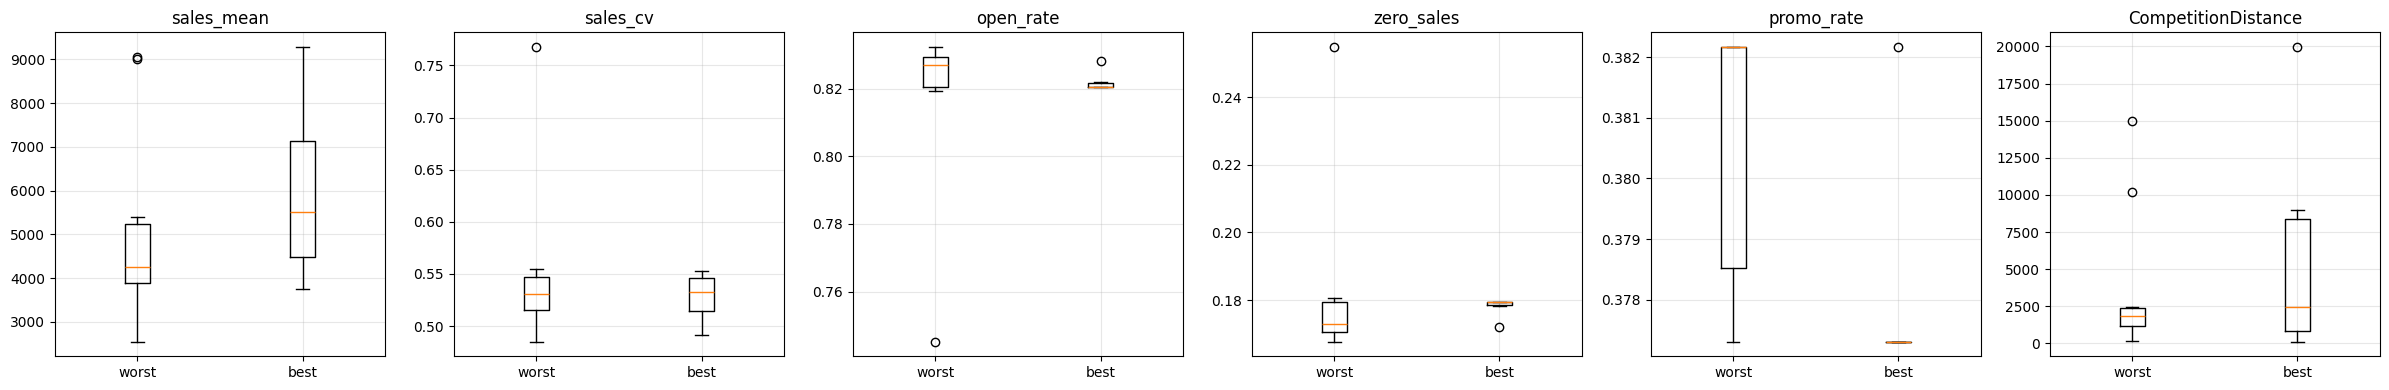


PROMO2 DETAIL

Promo2 counts:
group   best  worst
Promo2             
0          4      8
1          6      2

⚠️ PromoInterval was dropped from tranx (expected if you replaced it with is_promo2_month)

VERDICT

- If numeric means are nearly identical (small diff_pct, p > 0.10), the two
  groups are statistically indistinguishable -> 'worst' ranking is fold-luck.
- If one factor differs (p < 0.10) AND the direction is consistent, that factor
  may be real — but with n=10, confirm on ALL stores before acting.



In [58]:
# ==============================================================================
# STORE-LEVEL DIAGNOSTIC — worst vs best stores comparison
# Requires: train (BEFORE Open==1 filter ideally). No model / folds needed.
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

worst_stores = [108, 670, 532, 972, 73, 646, 597, 992, 237, 225]
best_stores  = [787, 498, 345, 76, 547, 539, 277, 902, 501, 159]

print("=" * 70)
print("WORST vs BEST STORES — PROFILE COMPARISON")
print("=" * 70)

# ------------------------------------------------------------------------------
# 1. PER-STORE AGGREGATE PROFILE
# ------------------------------------------------------------------------------
def store_profile(df, stores, label):
    sub = df[df["Store"].isin(stores)]
    prof = sub.groupby("Store").agg(
        n_rows       = ("Sales", "size"),
        n_open       = ("Open", lambda s: (s == 1).sum()),
        open_rate    = ("Open", "mean"),
        sales_mean   = ("Sales", "mean"),
        sales_std    = ("Sales", "std"),
        sales_median = ("Sales", "median"),
        sales_cv     = ("Sales", lambda s: s.std() / s.mean() if s.mean() else np.nan),
        sales_min    = ("Sales", "min"),
        sales_max    = ("Sales", "max"),
        zero_sales   = ("Sales", lambda s: (s == 0).mean()),
        promo_rate   = ("Promo", "mean") if "Promo" in df.columns else ("Sales", "size"),
    )
    # add ALL static store metadata THAT EXISTS
    static_candidates = ["StoreType", "Assortment", "CompetitionDistance",
                         "CompetitionOpenSinceMonth", "CompetitionOpenSinceYear",
                         "Promo2", "Promo2SinceWeek", "Promo2SinceYear",
                         "PromoInterval"]
    added = []
    for c in static_candidates:
        if c in df.columns:
            prof[c] = sub.groupby("Store")[c].first()
            added.append(c)
    prof["group"] = label
    if label == "worst":
        print("static store columns included in profile:", added)
    return prof

prof = pd.concat([
    store_profile(train, worst_stores, "worst"),
    store_profile(train, best_stores,  "best"),
])

print("\n--- Per-store profile ---")
print(prof.round(3).to_string())

# ------------------------------------------------------------------------------
# 2. GROUP-LEVEL MEAN COMPARISON
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("GROUP MEANS: worst vs best")
print("=" * 70)

num_profile_cols = [c for c in prof.columns
                    if pd.api.types.is_numeric_dtype(prof[c]) and c != "group"]
grp_means = prof.groupby("group")[num_profile_cols].mean().T
grp_means["diff"]     = grp_means["worst"] - grp_means["best"]
grp_means["diff_pct"] = (grp_means["diff"]
                         / grp_means["best"].replace(0, np.nan)) * 100
print(grp_means.round(3).to_string())

# ------------------------------------------------------------------------------
# 3. CATEGORICAL DISTRIBUTIONS (guarded)
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("CATEGORICAL DISTRIBUTIONS")
print("=" * 70)

cat_cols_present = [c for c in ["StoreType", "Assortment", "PromoInterval"]
                    if c in prof.columns]
if not cat_cols_present:
    print("⚠️ no categorical store columns present in train")
for c in cat_cols_present:
    print(f"\n--- {c} ---")
    print(pd.crosstab(prof[c].fillna("None"), prof["group"]).to_string())

# ------------------------------------------------------------------------------
# 4. STATISTICAL TESTS (n=10 — indicative only)
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("STATISTICAL TESTS (small sample — indicative only)")
print("=" * 70)

test_cols = [c for c in ["CompetitionDistance", "sales_mean", "sales_cv",
                         "open_rate", "zero_sales", "promo_rate", "Promo2"]
             if c in prof.columns]
for c in test_cols:
    w = prof.loc[prof["group"] == "worst", c].dropna()
    b = prof.loc[prof["group"] == "best",  c].dropna()
    if len(w) > 1 and len(b) > 1:
        t, p = stats.ttest_ind(w, b, equal_var=False)
        flag = "⚠️" if p < 0.10 else "  "
        print(f"{flag} {c:25s} worst={w.mean():10.2f}  "
              f"best={b.mean():10.2f}  t={t:6.2f}  p={p:.3f}")

# ------------------------------------------------------------------------------
# 5. VISUAL COMPARISON (guarded)
# ------------------------------------------------------------------------------
plot_cols = [c for c in ["sales_mean", "sales_cv", "open_rate",
                         "zero_sales", "promo_rate", "CompetitionDistance"]
             if c in prof.columns and pd.api.types.is_numeric_dtype(prof[c])]
if plot_cols:
    print("\nPlotting comparisons ...")
    fig, axes = plt.subplots(1, len(plot_cols), figsize=(4 * len(plot_cols), 4))
    if len(plot_cols) == 1:
        axes = [axes]
    for ax, c in zip(axes, plot_cols):
        data = [prof.loc[prof["group"] == "worst", c].dropna(),
                prof.loc[prof["group"] == "best",  c].dropna()]
        ax.boxplot(data, labels=["worst", "best"])
        ax.set_title(c); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

# ------------------------------------------------------------------------------
# 6. PROMO2 DETAIL (fully guarded)
# ------------------------------------------------------------------------------
if "Promo2" in prof.columns:
    print("\n" + "=" * 70)
    print("PROMO2 DETAIL")
    print("=" * 70)
    print("\nPromo2 counts:")
    print(pd.crosstab(prof["Promo2"], prof["group"]).to_string())

    if "PromoInterval" in prof.columns:
        print("\nPromoInterval for Promo2==1 stores:")
        p2 = prof[prof["Promo2"] == 1]
        if len(p2):
            print(pd.crosstab(p2["PromoInterval"].fillna("None"),
                              p2["group"]).to_string())
    else:
        print("\n⚠️ PromoInterval was dropped from train "
              "(expected if you replaced it with is_promo2_month)")
else:
    print("\n⚠️ Promo2 not present in train — skipping Promo2 detail")

# ------------------------------------------------------------------------------
# 7. VERDICT
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("VERDICT")
print("=" * 70)
print("""
- If numeric means are nearly identical (small diff_pct, p > 0.10), the two
  groups are statistically indistinguishable -> 'worst' ranking is fold-luck.
- If one factor differs (p < 0.10) AND the direction is consistent, that factor
  may be real — but with n=10, confirm on ALL stores before acting.
""")

In [60]:
train.drop("Store", axis=1, inplace=True)
train.drop("Customers", axis=1, inplace=True)
test.drop("Id", axis=1, inplace=True)
test.drop("Store", axis=1, inplace=True)
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 34 columns):
 #   Column                Non-Null Count    Dtype         
---  ------                --------------    -----         
 0   DayOfWeek             1017209 non-null  int64         
 1   Sales                 1017209 non-null  int64         
 2   Open                  1017209 non-null  int64         
 3   Promo                 1017209 non-null  int64         
 4   StateHoliday          1017209 non-null  object        
 5   SchoolHoliday         1017209 non-null  int64         
 6   Promo2                1017209 non-null  int64         
 7   IsSunday              1017209 non-null  int64         
 8   is_state_holiday      1017209 non-null  int64         
 9   is_public_holiday     1017209 non-null  int64         
 10  is_easter_holiday     1017209 non-null  int64         
 11  is_christmas_holiday  1017209 non-null  int64         
 12  state_hol_x_dow_1     1017209 non-null  in

**Randomforest model**

In [75]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.ensemble import RandomForestRegressor

# ===============================================================
# RMSPE metric (guards zero actuals)
# ===============================================================
def rmspe(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0                      # skip zero actuals
    if mask.sum() == 0:
        return np.nan
    return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2))

# ===============================================================
# 1. PARSE DATE FIRST (robust, format-independent)
# ===============================================================
train["Date"] = pd.to_datetime(train["Date"], errors="coerce")   # object -> datetime64
# if you know the format, be explicit instead:
# train["Date"] = pd.to_datetime(train["Date"], format="%Y-%m-%d", errors="coerce")

print("unparsed dates:", train["Date"].isna().sum())
print(train.columns)
# ===============================================================
# 2. SORT BY THE REAL DATETIME (always chronological)
# ===============================================================
# train = train.sort_values("Date").reset_index(drop=True)
# print("chronological:", train["Date"].is_monotonic_increasing)   # must be True

# keep a plain-date key for grouping (whole-day CV)
# train["_date_key"] = train["Date"].dt.normalize()

# ===============================================================
# 3. DERIVE DATE FEATURES, then drop raw datetime
# ===============================================================
train["date_int"]   = (train["Date"] - pd.Timestamp("1970-01-01")).dt.days.astype("Int64")
train["year"]       = train["Date"].dt.year
train["month"]      = train["Date"].dt.month
train["day"]        = train["Date"].dt.day
train["dayofweek"]  = train["Date"].dt.dayofweek            # 0=Mon
train["dayofyear"]  = train["Date"].dt.dayofyear
train["weekofyear"] = train["Date"].dt.isocalendar().week.astype("Int64")
train["quarter"]    = train["Date"].dt.quarter
train["is_weekend"] = (train["Date"].dt.dayofweek >= 5).astype(int)

# cyclical encodings
train["month_sin"] = np.sin(2 * np.pi * train["month"] / 12)
train["month_cos"] = np.cos(2 * np.pi * train["month"] / 12)
train["dow_sin"]   = np.sin(2 * np.pi * train["dayofweek"] / 7)
train["dow_cos"]   = np.cos(2 * np.pi * train["dayofweek"] / 7)

train = train.drop(columns=["Date"])                        # models can't use datetime64

# ===============================================================
# 4. FEATURES / TARGET
# ===============================================================
target_col = "Sales"                                  # <- your label column
drop_cols  = [target_col, "Id", "_date_key"]
feature_cols = [c for c in train.columns if c not in drop_cols]

X = train[feature_cols].copy()
y = train[target_col]

# ensure date_int is plain int64
X["date_int"] = X["date_int"].astype("int64")

# ===============================================================
# 5. PREPROCESSING + MODEL PIPELINE (fit per fold -> no leakage)
# ===============================================================
num_cols = X.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

pre = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale",  StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OrdinalEncoder(handle_unknown="use_encoded_value",
                                  unknown_value=-1)),
    ]), cat_cols),
])

model = Pipeline([
    ("pre", pre),
    ("reg", RandomForestRegressor(random_state=42)),
])

# ===============================================================
# 6. DATE-BASED EXPANDING WINDOW CV (whole dates only, no shared dates)
# ===============================================================
# ===============================================================
# 6. DATE-BASED EXPANDING WINDOW CV (whole dates only, no shared dates)
# ===============================================================
date_key = train["_date_key"]

# keep as pandas Timestamps so .date() works
unique_dates = pd.DatetimeIndex(sorted(date_key.dropna().unique()))
n_dates = len(unique_dates)

N_SPLITS = 5
edges = np.linspace(0, n_dates, N_SPLITS + 2).astype(int)

train_scores, val_scores = [], []

for fold in range(N_SPLITS):
    train_dates = unique_dates[:edges[fold + 1]]
    val_dates   = unique_dates[edges[fold + 1]:edges[fold + 2]]

    if len(val_dates) == 0 or len(train_dates) == 0:
        continue

    train_mask = date_key.isin(train_dates).to_numpy()
    val_mask   = date_key.isin(val_dates).to_numpy()

    shared = set(train_dates) & set(val_dates)
    assert len(shared) == 0, f"Fold {fold}: shared dates {shared}"

    X_tr, y_tr = X[train_mask], y[train_mask]
    X_val, y_val = X[val_mask], y[val_mask]

    model.fit(X_tr, y_tr)

    train_pred = np.clip(model.predict(X_tr), 0, None)
    val_pred   = np.clip(model.predict(X_val), 0, None)

    tr_score = rmspe(y_tr, train_pred)
    vl_score = rmspe(y_val, val_pred)
    train_scores.append(tr_score)
    val_scores.append(vl_score)

    print(f"Fold {fold+1}: "
          f"train RMSPE={tr_score:.4f} | val RMSPE={vl_score:.4f} | "
          f"train dates={len(train_dates)} "
          f"({pd.Timestamp(train_dates[0]).date()}..{pd.Timestamp(train_dates[-1]).date()}) | "
          f"val dates={len(val_dates)} "
          f"({pd.Timestamp(val_dates[0]).date()}..{pd.Timestamp(val_dates[-1]).date()}) | "
          f"shared dates={len(shared)}")

print(f"\nMean train RMSPE: {np.mean(train_scores):.4f} +/- {np.std(train_scores):.4f}")
print(f"Mean val   RMSPE: {np.mean(val_scores):.4f} +/- {np.std(val_scores):.4f}")

# ===============================================================
# 7. FINAL FIT ON ALL DATA -> predict on unlabeled test
# ===============================================================
# model.fit(X, y)

# apply the SAME date logic to test, then align columns
# test["Date"] = pd.to_datetime(test["Date"], errors="coerce")
# test["date_int"]   = (test["Date"] - pd.Timestamp("1970-01-01")).dt.days.astype("Int64")
# test["year"]       = test["Date"].dt.year
# test["month"]      = test["Date"].dt.month
# test["day"]        = test["Date"].dt.day
# test["dayofweek"]  = test["Date"].dt.dayofweek
# test["dayofyear"]  = test["Date"].dt.dayofyear
# test["weekofyear"] = test["Date"].dt.isocalendar().week.astype("Int64")
# test["quarter"]    = test["Date"].dt.quarter
# test["is_weekend"] = (test["Date"].dt.dayofweek >= 5).astype(int)
# test["month_sin"]  = np.sin(2 * np.pi * test["month"] / 12)
# test["month_cos"]  = np.cos(2 * np.pi * test["month"] / 12)
# test["dow_sin"]    = np.sin(2 * np.pi * test["dayofweek"] / 7)
# test["dow_cos"]    = np.cos(2 * np.pi * test["dayofweek"] / 7)
# test = test.drop(columns=["Date"])

# X_test = test.reindex(columns=feature_cols)            # same schema as training
# X_test["date_int"] = X_test["date_int"].astype("int64")

# preds_test = np.clip(model.predict(X_test), 0, None)
# results = pd.DataFrame({"Id": test["Id"], "pred": preds_test})
# results.to_csv("predictions.csv", index=False)
# print("\nSaved predictions.csv")

Index(['DayOfWeek', 'Sales', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday',
       'Promo2', 'IsSunday', 'is_state_holiday', 'is_public_holiday',
       'is_easter_holiday', 'is_christmas_holiday', 'state_hol_x_dow_1',
       'state_hol_x_dow_2', 'state_hol_x_dow_3', 'state_hol_x_dow_4',
       'state_hol_x_dow_5', 'state_hol_x_dow_6', 'state_hol_x_dow_7',
       'promo_x_sunday', '_date_key', 'date_int', 'year', 'month', 'day',
       'dayofweek', 'dayofyear', 'weekofyear', 'quarter', 'is_weekend',
       'month_sin', 'month_cos', 'dow_sin', 'dow_cos'],
      dtype='object')
Fold 1: train RMSPE=0.5723 | val RMSPE=0.5409 | train dates=157 (2013-01-01..2013-06-06) | val dates=157 (2013-06-07..2013-11-10) | shared dates=0
Fold 2: train RMSPE=0.5252 | val RMSPE=0.4783 | train dates=314 (2013-01-01..2013-11-10) | val dates=157 (2013-11-11..2014-04-16) | shared dates=0
Fold 3: train RMSPE=0.5090 | val RMSPE=0.5263 | train dates=471 (2013-01-01..2014-04-16) | val dates=157 (2014-04-17..20

In [16]:
# 1. CUDA visible?
!nvidia-smi
# expect: Tesla T4, 16GB

# 2. XGBoost GPU?
import xgboost as xgb
print("xgb version:", xgb.__version__)
xgb.train({"tree_method": "hist", "device": "cuda"},
          xgb.DMatrix(np.random.rand(100, 5), label=np.random.rand(100)), num_boost_round=2)
# no error -> GPU works

# 3. LightGBM GPU? (needs GPU build)
import lightgbm as lgb
print("lgb version:", lgb.__version__)
# if this raises "GPU Tree Learner was not enabled", reinstall GPU build

# 4. CatBoost GPU?
from catboost import CatBoostRegressor
print("catboost version:", __import__("catboost").__version__)
# CatBoost wheel on PyPI supports GPU by default (task_type="GPU")

Sun Nov 15 16:30:14 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

**XGBoost, CatBoost and LightGBM models**

In [20]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor

# ===============================================================
# 0. GPU AVAILABILITY CHECK
# ===============================================================
try:
    import torch
    print("torch CUDA available:", torch.cuda.is_available(),
          "| device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
except ImportError:
    print("torch not installed — skipping torch CUDA check")

import subprocess
try:
    print(subprocess.check_output(["nvidia-smi", "--query-gpu=name,memory.total",
                                   "--format=csv,noheader"]).decode().strip())
except Exception as e:
    print("nvidia-smi unavailable:", e)

# ===============================================================
# RMSPE metric (guards zero actuals)
# ===============================================================
def rmspe(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2))

# ===============================================================
# 1. PARSE DATE FIRST
# ===============================================================
train["Date"] = pd.to_datetime(train["Date"], errors="coerce")
print("unparsed dates:", train["Date"].isna().sum())

# # # ===============================================================
# # # 2. SORT BY DATETIME
# # # ===============================================================
train = train.sort_values("Date").reset_index(drop=True)
print("chronological:", train["Date"].is_monotonic_increasing)
train["_date_key"] = train["Date"].dt.normalize()

# # # ===============================================================
# # # 3. DATE FEATURES
# # # ===============================================================
train["date_int"]   = (train["Date"] - pd.Timestamp("1970-01-01")).dt.days.astype("Int64")
train["year"]       = train["Date"].dt.year
train["month"]      = train["Date"].dt.month
train["day"]        = train["Date"].dt.day
train["dayofweek"]  = train["Date"].dt.dayofweek
train["dayofyear"]  = train["Date"].dt.dayofyear
train["weekofyear"] = train["Date"].dt.isocalendar().week.astype("Int64")
train["quarter"]    = train["Date"].dt.quarter
train["is_weekend"] = (train["Date"].dt.dayofweek >= 5).astype(int)
train["month_sin"]  = np.sin(2 * np.pi * train["month"] / 12)
train["month_cos"]  = np.cos(2 * np.pi * train["month"] / 12)
train["dow_sin"]    = np.sin(2 * np.pi * train["dayofweek"] / 7)
train["dow_cos"]    = np.cos(2 * np.pi * train["dayofweek"] / 7)
train = train.drop(columns=["Date"])

# ===============================================================
# 3. FEATURES / TARGET
# ===============================================================
target_col = "Sales"
drop_cols  = [c for c in [target_col, "Id", "_date_key"] if c in train.columns]
feature_cols = [c for c in train.columns if c not in drop_cols]

X = train[feature_cols].copy()
y = train[target_col]
X["date_int"] = X["date_int"].astype("int64")

num_cols = X.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

print(f"numeric cols: {len(num_cols)}, categorical cols: {len(cat_cols)}")

# ===============================================================
# 4. PREPROCESSING (shared for LGBM/XGB; CatBoost native cats)
# ===============================================================
pre_numeric = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale",  StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OrdinalEncoder(handle_unknown="use_encoded_value",
                                  unknown_value=-1)),
    ]), cat_cols),
])

pre_catboost = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", "passthrough", cat_cols),
])

# ===============================================================
# 5. THREE GPU MODEL PIPELINES
# ===============================================================
# --- LightGBM GPU ---
# NOTE: requires a GPU-enabled LightGBM build. If `device="gpu"` errors,
#   install: pip uninstall lightgbm && pip install lightgbm --config-settings=cmake.define.USE_GPU=ON
pipeline_lgbm = Pipeline([
    ("pre", pre_numeric),
    ("reg", lgb.LGBMRegressor(
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=63,
        min_child_samples=20,
        subsample=0.8,
        colsample_bytree=0.8,
        device="gpu",                     # <- GPU
        gpu_platform_id=0,
        gpu_device_id=0,
        random_state=42,
        n_jobs=-1,
        verbose=-1,
    )),
])

# --- XGBoost GPU (XGB >= 2.0 syntax; see fallback below for older versions) ---
pipeline_xgb = Pipeline([
    ("pre", pre_numeric),
    ("reg", xgb.XGBRegressor(
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",               # <- hist + device=cuda is GPU
        device="cuda",                    # XGB >= 2.0
        random_state=42,
        n_jobs=-1,
        verbosity=0,
    )),
])

# --- CatBoost GPU ---
cat_feature_indices = list(range(len(num_cols), len(num_cols) + len(cat_cols)))

pipeline_cat = Pipeline([
    ("pre", pre_catboost),
    ("reg", CatBoostRegressor(
        iterations=1000,
        learning_rate=0.05,
        depth=6,
        random_seed=42,
        cat_features=cat_feature_indices,    # <- INDICES, not names
        task_type="GPU",
        devices="0",
        verbose=0,
        allow_writing_files=False,
    )),
])

models = {
    "LightGBM-GPU": pipeline_lgbm,
    "XGBoost-GPU":  pipeline_xgb,
    "CatBoost-GPU": pipeline_cat,
}

# ===============================================================
# 6. GPU FALLBACKS (if any GPU flag fails on your setup)
# ===============================================================
# Older XGBoost (<2.0):  use tree_method="gpu_hist" and drop device="cuda"
#   XGBRegressor(..., tree_method="gpu_hist", predictor="gpu_predictor")
#
# If LightGBM device="gpu" raises "GPU Tree Learner was not enabled",
# your wheel isn't GPU-built. Reinstall:
#   pip uninstall -y lightgbm
#   pip install lightgbm --config-settings=cmake.define.USE_GPU=ON
# Or fall back to CPU by setting device="cpu".
#
# If CatBoost GPU OOMs on T4, reduce depth or iterations, or set task_type="CPU".

# ===============================================================
# 7. DATE-BASED EXPANDING WINDOW CV
# ===============================================================
date_key = train["_date_key"]
unique_dates = pd.DatetimeIndex(sorted(date_key.dropna().unique()))
n_dates = len(unique_dates)

N_SPLITS = 5
edges = np.linspace(0, n_dates, N_SPLITS + 2).astype(int)

results = {name: {"train": [], "val": [], "fold_preds": []} for name in models}

for fold in range(N_SPLITS):
    train_dates = unique_dates[:edges[fold + 1]]
    val_dates   = unique_dates[edges[fold + 1]:edges[fold + 2]]
    if len(val_dates) == 0 or len(train_dates) == 0:
        continue

    train_mask = date_key.isin(train_dates).to_numpy()
    val_mask   = date_key.isin(val_dates).to_numpy()
    assert len(set(train_dates) & set(val_dates)) == 0

    X_tr, y_tr = X[train_mask], y[train_mask]
    X_val, y_val = X[val_mask], y[val_mask]

    print(f"\n--- Fold {fold+1}: "
          f"train {len(train_dates)} dates | val {len(val_dates)} dates ---")

    for name, pipe in models.items():
        try:
            pipe.fit(X_tr, y_tr)
        except Exception as e:
            print(f"  {name}: ❌ fit failed — {type(e).__name__}: {e}")
            results[name]["train"].append(np.nan)
            results[name]["val"].append(np.nan)
            results[name]["fold_preds"].append(None)
            continue

        train_pred = np.clip(pipe.predict(X_tr), 0, None)
        val_pred   = np.clip(pipe.predict(X_val), 0, None)

        tr_score = rmspe(y_tr, train_pred)
        vl_score = rmspe(y_val, val_pred)

        results[name]["train"].append(tr_score)
        results[name]["val"].append(vl_score)
        results[name]["fold_preds"].append({
            "fold": fold + 1,
            "val_idx": np.where(val_mask)[0],
            "y_val": y_val.values,
            "pred_val": val_pred,
        })

        print(f"  {name:14s}: train RMSPE={tr_score:.4f} | val RMSPE={vl_score:.4f}")

# ===============================================================
# 8. FINAL SUMMARY / COMPARISON
# ===============================================================
print("\n" + "=" * 70)
print("FINAL SUMMARY — GPU models")
print("=" * 70)

summary_rows = []
for name, r in results.items():
    vals = [v for v in r["val"] if not np.isnan(v)]
    if not vals:
        continue
    summary_rows.append({
        "model":      name,
        "mean_train": np.nanmean(r["train"]),
        "std_train":  np.nanstd(r["train"]),
        "mean_val":   np.mean(vals),
        "std_val":    np.std(vals),
        "min_val":    np.min(vals),
        "max_val":    np.max(vals),
    })
summary = pd.DataFrame(summary_rows).sort_values("mean_val")
print(summary.round(4).to_string(index=False))

if len(summary):
    best_model_name = summary.iloc[0]["model"]
    print(f"\n🏆 Best by mean val RMSPE: {best_model_name} "
          f"({summary.iloc[0]['mean_val']:.4f})")

print("\nPer-fold val RMSPE:")
fold_table = pd.DataFrame({"fold": range(1, N_SPLITS + 1)})
for name, r in results.items():
    fold_table[name] = r["val"]
print(fold_table.round(4).to_string(index=False))

# ===============================================================
# 9. FINAL FIT (best model) -> predict on test
# ===============================================================
# best_pipe = models[best_model_name]
# best_pipe.fit(X, y)
#
# test["Date"] = pd.to_datetime(test["Date"], errors="coerce")
# test["date_int"]   = (test["Date"] - pd.Timestamp("1970-01-01")).dt.days.astype("Int64")
# test["year"]       = test["Date"].dt.year
# test["month"]      = test["Date"].dt.month
# test["day"]        = test["Date"].dt.day
# test["dayofweek"]  = test["Date"].dt.dayofweek
# test["dayofyear"]  = test["Date"].dt.dayofyear
# test["weekofyear"] = test["Date"].dt.isocalendar().week.astype("Int64")
# test["quarter"]    = test["Date"].dt.quarter
# test["is_weekend"] = (test["Date"].dt.dayofweek >= 5).astype(int)
# test["month_sin"]  = np.sin(2 * np.pi * test["month"] / 12)
# test["month_cos"]  = np.cos(2 * np.pi * test["month"] / 12)
# test["dow_sin"]    = np.sin(2 * np.pi * test["dayofweek"] / 7)
# test["dow_cos"]    = np.cos(2 * np.pi * test["dayofweek"] / 7)
# test = test.drop(columns=["Date"])
# if "Open" in test.columns:
#     test = test[test["Open"] == 1].reset_index(drop=True)   # if scoring open days only
#     test = test.drop(columns=["Open"])
#
# X_test = test.reindex(columns=feature_cols)
# X_test["date_int"] = X_test["date_int"].astype("int64")
# preds_test = np.clip(best_pipe.predict(X_test), 0, None)
# pd.DataFrame({"Id": test["Id"], "pred": preds_test}).to_csv("predictions.csv", index=False)
# print("\nSaved predictions.csv")

torch CUDA available: True | device: Tesla T4
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB
numeric cols: 30, categorical cols: 1

--- Fold 1: train 157 dates | val 157 dates ---


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


  LightGBM-GPU  : train RMSPE=0.5732 | val RMSPE=0.5616
  XGBoost-GPU   : train RMSPE=0.5733 | val RMSPE=0.5186
  CatBoost-GPU  : train RMSPE=0.5766 | val RMSPE=0.5260

--- Fold 2: train 314 dates | val 157 dates ---


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


  LightGBM-GPU  : train RMSPE=0.5268 | val RMSPE=0.4996
  XGBoost-GPU   : train RMSPE=0.5271 | val RMSPE=0.4965
  CatBoost-GPU  : train RMSPE=0.5282 | val RMSPE=0.4999

--- Fold 3: train 471 dates | val 157 dates ---


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


  LightGBM-GPU  : train RMSPE=0.5109 | val RMSPE=0.5450
  XGBoost-GPU   : train RMSPE=0.5111 | val RMSPE=0.6443
  CatBoost-GPU  : train RMSPE=0.5128 | val RMSPE=0.5675

--- Fold 4: train 628 dates | val 157 dates ---


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


  LightGBM-GPU  : train RMSPE=0.5026 | val RMSPE=0.6291
  XGBoost-GPU   : train RMSPE=0.5032 | val RMSPE=0.6203
  CatBoost-GPU  : train RMSPE=0.5051 | val RMSPE=0.6441

--- Fold 5: train 785 dates | val 157 dates ---


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


  LightGBM-GPU  : train RMSPE=0.5243 | val RMSPE=0.4786
  XGBoost-GPU   : train RMSPE=0.5249 | val RMSPE=0.4790
  CatBoost-GPU  : train RMSPE=0.5274 | val RMSPE=0.4859

FINAL SUMMARY — GPU models
       model  mean_train  std_train  mean_val  std_val  min_val  max_val
LightGBM-GPU      0.5276     0.0245    0.5428   0.0525   0.4786   0.6291
CatBoost-GPU      0.5300     0.0249    0.5447   0.0569   0.4859   0.6441
 XGBoost-GPU      0.5279     0.0243    0.5517   0.0674   0.4790   0.6443

🏆 Best by mean val RMSPE: LightGBM-GPU (0.5428)

Per-fold val RMSPE:
 fold  LightGBM-GPU  XGBoost-GPU  CatBoost-GPU
    1        0.5616       0.5186        0.5260
    2        0.4996       0.4965        0.4999
    3        0.5450       0.6443        0.5675
    4        0.6291       0.6203        0.6441
    5        0.4786       0.4790        0.4859


In [21]:
# ===============================================================
# 8b. POOLED FINAL RMSPE (all validation predictions concatenated)
# ===============================================================
print("\n" + "=" * 70)
print("POOLED FINAL RMSPE (all val rows pooled across folds)")
print("=" * 70)

pooled_rows = []
for name, r in results.items():
    if not r["fold_preds"]:
        continue

    # concatenate y_val and predictions across all folds
    y_all    = np.concatenate([fp["y_val"]    for fp in r["fold_preds"] if fp is not None])
    pred_all = np.concatenate([fp["pred_val"] for fp in r["fold_preds"] if fp is not None])

    pooled = rmspe(y_all, pred_all)

    # also compute per-fold for comparison
    fold_scores = [s for s in r["val"] if not np.isnan(s)]

    pooled_rows.append({
        "model":         name,
        "pooled_rmspe":  pooled,                # <<< the real "final" RMSPE
        "mean_of_folds": np.mean(fold_scores),  # what the old summary showed
        "std_of_folds":  np.std(fold_scores),
        "n_val_rows":    len(y_all),
    })

pooled_df = pd.DataFrame(pooled_rows).sort_values("pooled_rmspe")
print(pooled_df.round(4).to_string(index=False))

best_pooled = pooled_df.iloc[0]
print(f"\n🏆 Best by POOLED RMSPE: {best_pooled['model']} "
      f"({best_pooled['pooled_rmspe']:.4f} on {best_pooled['n_val_rows']:,} rows)")

# show the gap between pooled and mean-of-folds
pooled_df["gap"] = pooled_df["mean_of_folds"] - pooled_df["pooled_rmspe"]
print("\n(mean_of_folds vs pooled_rmspe — gap shows fold-size weighting effect):")
print(pooled_df[["model", "pooled_rmspe", "mean_of_folds", "gap"]]
      .round(4).to_string(index=False))


POOLED FINAL RMSPE (all val rows pooled across folds)
       model  pooled_rmspe  mean_of_folds  std_of_folds  n_val_rows
LightGBM-GPU        0.5432         0.5428        0.0525      842155
CatBoost-GPU        0.5447         0.5447        0.0569      842155
 XGBoost-GPU        0.5522         0.5517        0.0674      842155

🏆 Best by POOLED RMSPE: LightGBM-GPU (0.5432 on 842,155 rows)

(mean_of_folds vs pooled_rmspe — gap shows fold-size weighting effect):
       model  pooled_rmspe  mean_of_folds     gap
LightGBM-GPU        0.5432         0.5428 -0.0005
CatBoost-GPU        0.5447         0.5447 -0.0000
 XGBoost-GPU        0.5522         0.5517 -0.0005
